# 02 建模结果：交叉验证、验证集比较与校准

训练与选择由 `python -m src.train` 完成（结果写入 `reports/model_results.json` 和 `data/processed/valid_predictions.csv`）。
本 notebook 只读取这些结果作图，不重新训练，也不读取测试集。

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
R = json.loads((ROOT / "reports" / "model_results.json").read_text(encoding="utf-8"))
V = pd.read_csv(ROOT / "data" / "processed" / "valid_predictions.csv")
y = V["target"].to_numpy()

BLUE, ORANGE, AQUA, GRAY, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"], "axes.unicode_minus": False,
    "figure.dpi": 110, "savefig.dpi": 200, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False,
})
save = lambda fig, name: fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
LABEL = {"baseline": "基准（训练集违约率）", "lr_none": "逻辑回归", "lr_sigmoid": "逻辑回归 + Platt",
         "lr_isotonic": "逻辑回归 + 保序回归", "rf_none": "随机森林", "rf_sigmoid": "随机森林 + Platt",
         "rf_isotonic": "随机森林 + 保序回归"}
print("选定模型：", R["chosen"])

选定模型： lr_none


## 表 1 训练集 5 折交叉验证（调参 + 特征消融）

In [2]:
cv = pd.DataFrame(R["cv"])
cv["model"] = cv["model"].map({"lr": "逻辑回归", "rf": "随机森林"})
cv[["model", "features", "cv_auc", "cv_auc_sd", "cv_brier", "best_params"]].round(4)

,model,features,cv_auc,cv_auc_sd,cv_brier,best_params
0,逻辑回归,raw,0.7735,0.0031,0.1371,{'C': 0.01}
1,逻辑回归,raw+eng,0.7786,0.0044,0.1355,{'C': 0.1}
2,随机森林,raw,0.7840,0.0027,0.1349,"{'max_depth': 14, 'max_features': 'sqrt', 'min..."
3,随机森林,raw+eng,0.7869,0.0042,0.1339,"{'max_depth': 14, 'max_features': 0.33, 'min_s..."


## 表 2 验证集指标

In [3]:
vm = pd.DataFrame(R["valid"]).T.rename(index=LABEL)
vm[["roc_auc", "ks", "pr_auc", "ap", "brier", "log_loss", "ece", "mean_p"]].round(4)

,roc_auc,ks,pr_auc,ap,brier,log_loss,ece,mean_p
基准（训练集违约率）,0.5000,0.0000,0.6106,0.2211,0.1722,0.5283,0.0207,0.2212
逻辑回归,0.7835,0.4328,0.5689,0.5692,0.1325,0.4250,0.0159,0.2146
逻辑回归 + Platt,0.7835,0.4328,0.5689,0.5692,0.1325,0.4251,0.0164,0.2147
逻辑回归 + 保序回归,0.7832,0.4296,0.5690,0.5561,0.1324,0.4248,0.0116,0.2142
随机森林,0.7884,0.4422,0.5711,0.5716,0.1314,0.4210,0.0121,0.2157
随机森林 + Platt,0.7884,0.4422,0.5711,0.5716,0.1316,0.4229,0.0208,0.2150
随机森林 + 保序回归,0.7872,0.4357,0.5746,0.5574,0.1316,0.4215,0.0110,0.2154


In [4]:
b = R["bootstrap_rf_minus_lr"]
print(f"AUC(随机森林) − AUC(逻辑回归) = {b['diff']:.4f}，95% bootstrap 区间 [{b['ci95'][0]:.4f}, {b['ci95'][1]:.4f}]")

AUC(随机森林) − AUC(逻辑回归) = 0.0049，95% bootstrap 区间 [-0.0034, 0.0132]


## 图 9 ROC 与 Precision–Recall 曲线（验证集）

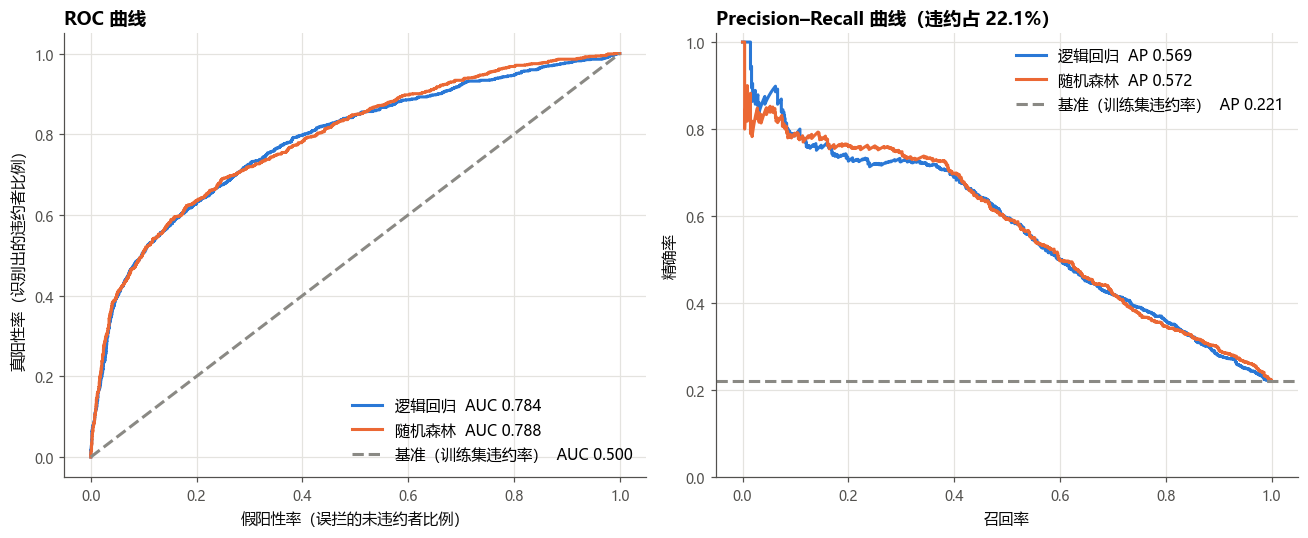

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
series = [("lr_none", BLUE, "-"), ("rf_none", ORANGE, "-"), ("baseline", GRAY, "--")]
for key, col, ls in series:
    p = V[f"p_{key}"]; m = R["valid"][key]
    fpr, tpr, _ = roc_curve(y, p)
    axs[0].plot(fpr, tpr, color=col, lw=2, ls=ls, label=f"{LABEL[key]}  AUC {m['roc_auc']:.3f}")
    if key == "baseline":  # 常数得分没有排序，PR 曲线退化为一条水平线（精确率 = 违约占比）
        axs[1].axhline(y.mean(), color=col, lw=2, ls=ls, label=f"{LABEL[key]}  AP {m['ap']:.3f}")
        continue
    prec, rec, _ = precision_recall_curve(y, p)
    axs[1].plot(rec, prec, color=col, lw=2, ls=ls, label=f"{LABEL[key]}  AP {m['ap']:.3f}")
axs[0].set(xlabel="假阳性率（误拦的未违约者比例）", ylabel="真阳性率（识别出的违约者比例）")
axs[0].set_title("ROC 曲线", loc="left"); axs[0].legend(loc="lower right")
axs[1].set(xlabel="召回率", ylabel="精确率", ylim=(0, 1.02))
axs[1].set_title("Precision–Recall 曲线（违约占 22.1%）", loc="left"); axs[1].legend(loc="upper right")
fig.tight_layout(); save(fig, "fig9_roc_pr"); plt.show()

## 图 10 校准曲线（验证集，按预测概率十分位分箱）

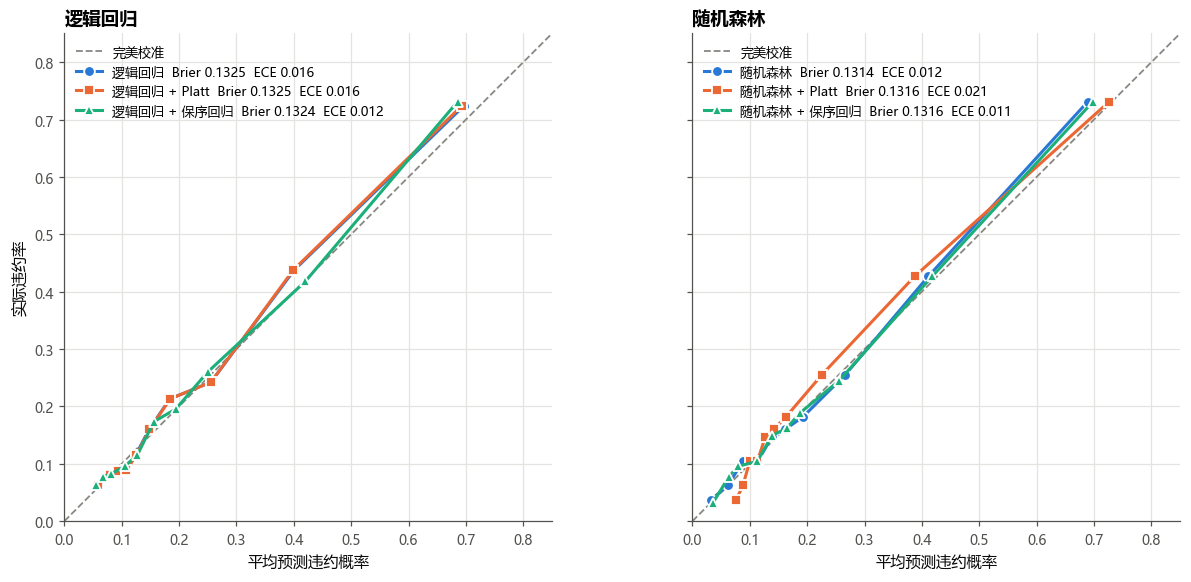

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True)
for ax, fam, name in [(axs[0], "lr", "逻辑回归"), (axs[1], "rf", "随机森林")]:
    ax.plot([0, 1], [0, 1], color=GRAY, lw=1.2, ls="--", label="完美校准")
    for meth, col, mk in [("none", BLUE, "o"), ("sigmoid", ORANGE, "s"), ("isotonic", AQUA, "^")]:
        key = f"{fam}_{meth}"; t = pd.DataFrame(R["calibration"][key])
        ax.plot(t["mean_p"], t["obs"], color=col, lw=2, marker=mk, ms=7, mec="white", mew=1.2,
                label=f"{LABEL[key]}  Brier {R['valid'][key]['brier']:.4f}  ECE {R['valid'][key]['ece']:.3f}")
    ax.set(xlim=(0, 0.85), ylim=(0, 0.85), xlabel="平均预测违约概率", aspect="equal")
    ax.set_title(name, loc="left"); ax.legend(loc="upper left", fontsize=8.5)
axs[0].set_ylabel("实际违约率")
fig.tight_layout(); save(fig, "fig10_calibration"); plt.show()

## 图 11 模型解释（全训练集拟合的未校准模型）

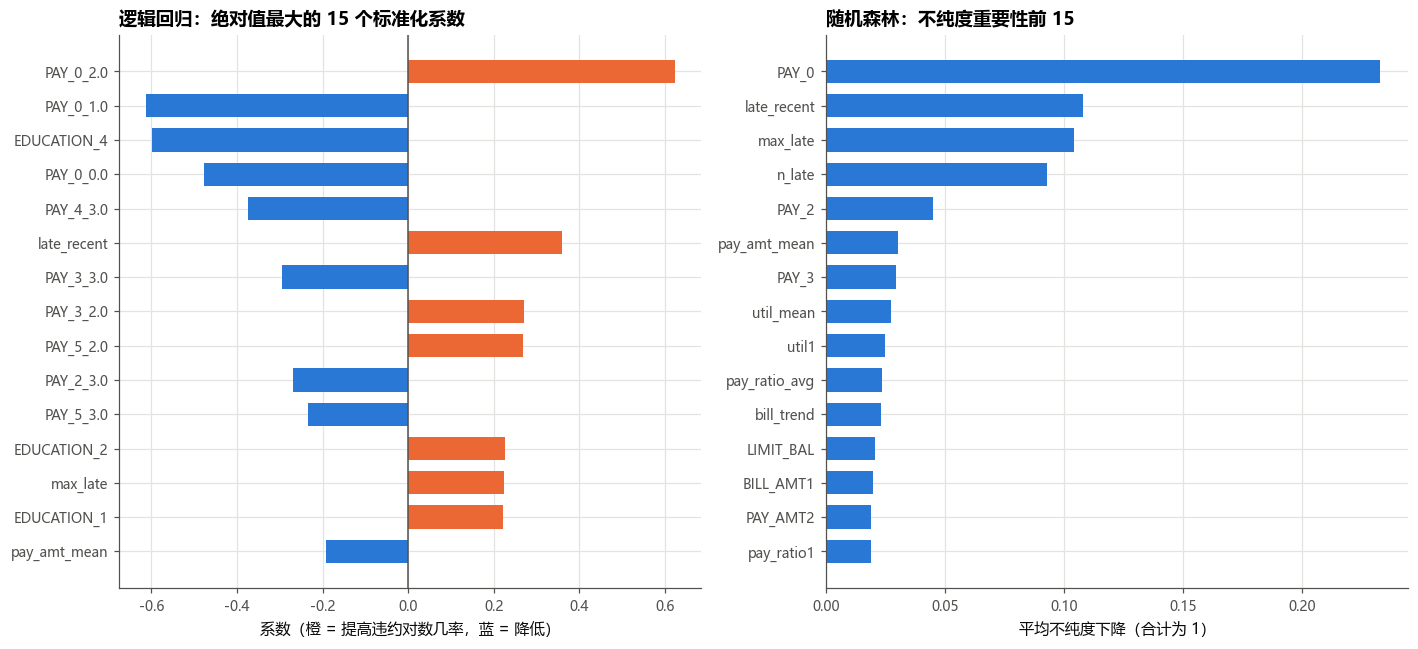

In [7]:
def pretty(n):
    return n.split("__", 1)[1] if "__" in n else n
fig, axs = plt.subplots(1, 2, figsize=(13, 6))
lr = pd.Series(R["explain"]["lr"]).head(15)[::-1]
axs[0].barh([pretty(n) for n in lr.index], lr.values, color=[ORANGE if v > 0 else BLUE for v in lr.values], height=0.68)
axs[0].axvline(0, color=MUTED, lw=1)
axs[0].set_title("逻辑回归：绝对值最大的 15 个标准化系数", loc="left")
axs[0].set_xlabel("系数（橙 = 提高违约对数几率，蓝 = 降低）")
rf = pd.Series(R["explain"]["rf"]).head(15)[::-1]
axs[1].barh([pretty(n) for n in rf.index], rf.values, color=BLUE, height=0.68)
axs[1].set_title("随机森林：不纯度重要性前 15", loc="left"); axs[1].set_xlabel("平均不纯度下降（合计为 1）")
fig.tight_layout(); save(fig, "fig11_explain"); plt.show()

## 图 12 选定模型的预测概率分布（验证集，供阶段 ③ 选阈值参考）

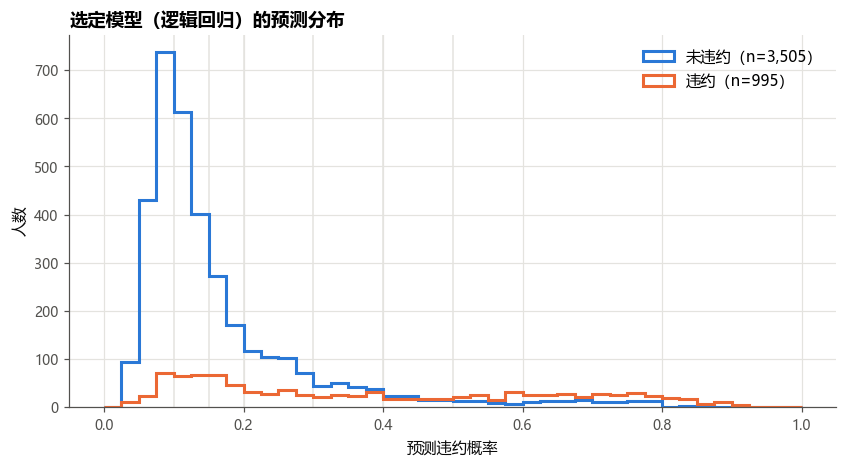

In [8]:
p = V[f"p_{R['chosen']}"]
fig, ax = plt.subplots(figsize=(9, 4.4))
bins = np.linspace(0, 1, 41)
for t, col, lab in [(0, BLUE, "未违约"), (1, ORANGE, "违约")]:
    ax.hist(p[y == t], bins=bins, histtype="step", lw=2, color=col, label=f"{lab}（n={int((y == t).sum()):,}）")
for t in (0.10, 0.15, 0.20, 0.30, 0.40, 0.50):
    ax.axvline(t, color=GRID, lw=1, zorder=0)
ax.set(xlabel="预测违约概率", ylabel="人数")
ax.set_title(f"选定模型（{LABEL[R['chosen']]}）的预测分布", loc="left"); ax.legend()
save(fig, "fig12_pred_dist"); plt.show()